In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 20)

# Plot settings
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Load the climate dataset
DATA_PATH = Path("../data/Kathmandu_Daily_Climate_Data.csv")

df = pd.read_csv(DATA_PATH)

# Create a date column
df["DATE"] = pd.to_datetime(
    df["YEAR"].astype(str)
    + df["DOY"].astype(str).str.zfill(3),
    format="%Y%j"
)

# Sort data by date
df = df.sort_values("DATE").reset_index(drop=True)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (15340, 21)


,YEAR,DOY,T2M,T2MWET,TS,T2M_RANGE,T2M_MAX,T2M_MIN,QV2M,RH2M,PRECTOTCORR,PS,WS2M,WS2M_MAX,WS2M_MIN,WS2M_RANGE,WS10M,WS10M_MAX,WS10M_MIN,WS10M_RANGE,DATE
0,1982,1,10.93,4.36,8.14,11.92,18.41,6.48,3.78,41.69,0.0,87.60,1.12,3.20,0.16,3.03,1.67,4.32,0.30,4.02,1982-01-01
1,1982,2,10.20,3.57,7.24,11.12,17.26,6.15,3.54,41.00,0.0,87.45,1.17,3.52,0.08,3.45,1.66,4.73,0.07,4.66,1982-01-02
2,1982,3,11.08,4.43,8.07,11.27,17.80,6.52,3.78,41.19,0.0,87.49,1.01,3.05,0.04,3.02,1.45,4.05,0.01,4.05,1982-01-03
3,1982,4,13.26,6.25,10.29,10.85,20.05,9.19,4.15,39.25,0.0,87.71,1.22,3.06,0.30,2.77,1.76,4.08,0.44,3.64,1982-01-04
4,1982,5,14.07,8.05,11.19,10.42,20.92,10.49,5.25,46.62,0.0,87.67,1.68,4.02,0.66,3.36,2.51,5.52,1.07,4.45,1982-01-05


In [3]:
# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check column names and data types
print("\nDataset information:")
df.info()

# Generate descriptive statistics
print("\nDescriptive statistics:")
display(df.describe().T)

Dataset shape: (15340, 21)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 15340 entries, 0 to 15339
Data columns (total 21 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   YEAR         15340 non-null  int64         
 1   DOY          15340 non-null  int64         
 2   T2M          15340 non-null  float64       
 3   T2MWET       15340 non-null  float64       
 4   TS           15340 non-null  float64       
 5   T2M_RANGE    15340 non-null  float64       
 6   T2M_MAX      15340 non-null  float64       
 7   T2M_MIN      15340 non-null  float64       
 8   QV2M         15340 non-null  float64       
 9   RH2M         15340 non-null  float64       
 10  PRECTOTCORR  15340 non-null  float64       
 11  PS           15340 non-null  float64       
 12  WS2M         15340 non-null  float64       
 13  WS2M_MAX     15340 non-null  float64       
 14  WS2M_MIN     15340 non-null  float64       
 15  WS2M_RANGE   15

,count,mean,min,25%,50%,75%,max,std
YEAR,15340.0,2002.499674,1982.0,1992.0,2002.5,2013.0,2023.0,12.120919
DOY,15340.0,183.119296,1.0,92.0,183.0,274.0,366.0,105.438628
T2M,15340.0,19.202557,4.12,14.7975,20.66,23.15,30.11,5.031258
T2MWET,15340.0,13.856804,-2.92,7.93,14.41,20.53,23.75,6.609551
TS,15340.0,18.470047,2.6,12.46,20.43,23.65,31.46,6.468848
...,...,...,...,...,...,...,...,...
WS10M,15340.0,2.188517,0.83,1.78,2.13,2.54,5.34,0.536365
WS10M_MAX,15340.0,4.533397,1.39,3.79,4.47,5.2,10.6,1.035791
WS10M_MIN,15340.0,0.554595,0.0,0.27,0.49,0.77,3.2,0.362642
WS10M_RANGE,15340.0,3.978746,0.76,3.3,3.95,4.61,9.11,0.959771


In [4]:
# 1. Check missing values
print("Missing values in each column:")
print(df.isnull().sum())

# 2. Check duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

# 3. Check duplicate dates
print("Number of duplicate dates:", df["DATE"].duplicated().sum())

# 4. Check date range
print("\nFirst date:", df["DATE"].min())
print("Last date:", df["DATE"].max())

# 5. Check whether dates are in chronological order
print(
    "Dates are sorted:",
    df["DATE"].is_monotonic_increasing
)

# 6. Check missing calendar days
expected_dates = pd.date_range(
    start=df["DATE"].min(),
    end=df["DATE"].max(),
    freq="D"
)

missing_dates = expected_dates.difference(df["DATE"])

print("Number of missing calendar days:", len(missing_dates))

if len(missing_dates) > 0:
    print("First missing dates:", missing_dates[:10])

Missing values in each column:
YEAR           0
DOY            0
T2M            0
T2MWET         0
TS             0
              ..
WS10M          0
WS10M_MAX      0
WS10M_MIN      0
WS10M_RANGE    0
DATE           0
Length: 21, dtype: int64

Number of duplicate rows: 0
Number of duplicate dates: 0

First date: 1982-01-01 00:00:00
Last date: 2023-12-31 00:00:00
Dates are sorted: True
Number of missing calendar days: 0


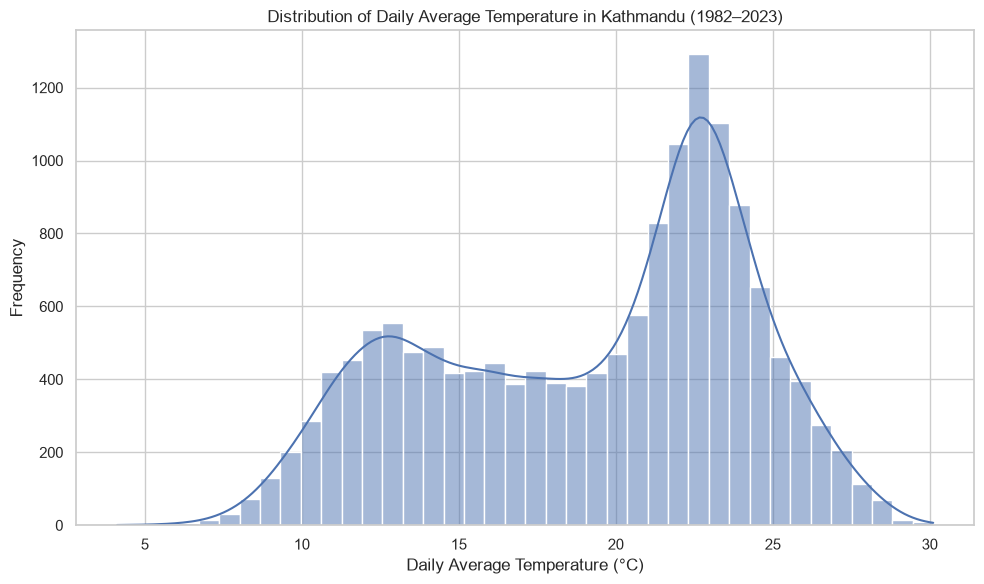

Figure saved successfully.


In [5]:
# Create output directory
output_dir = Path("outputs/figures")
if not output_dir.exists():
    output_dir = Path("../outputs/figures")

output_dir.mkdir(parents=True, exist_ok=True)

# Plot temperature distribution
plt.figure(figsize=(10, 6))

sns.histplot(
    df["T2M"],
    bins=40,
    kde=True
)

plt.title("Distribution of Daily Average Temperature in Kathmandu (1982–2023)")
plt.xlabel("Daily Average Temperature (°C)")
plt.ylabel("Frequency")
plt.tight_layout()

# Save figure
plt.savefig(
    output_dir / "temperature_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved successfully.")

In [6]:
print("Temperature Distribution Summary")
print("---------------------------------")
print("Mean:", round(df["T2M"].mean(), 2), "°C")
print("Median:", round(df["T2M"].median(), 2), "°C")
print("Standard Deviation:", round(df["T2M"].std(), 2), "°C")
print("Minimum:", round(df["T2M"].min(), 2), "°C")
print("Maximum:", round(df["T2M"].max(), 2), "°C")
print("Skewness:", round(df["T2M"].skew(), 3))

Temperature Distribution Summary
---------------------------------
Mean: 19.2 °C
Median: 20.66 °C
Standard Deviation: 5.03 °C
Minimum: 4.12 °C
Maximum: 30.11 °C
Skewness: -0.385


Average Daily Temperature by Month:
MONTH
1     11.16
2     13.52
3     18.18
4     22.55
5     24.56
6     25.13
7     23.43
8     22.82
9     21.62
10    19.19
11    15.64
12    12.39
Name: T2M, dtype: float64

Warmest month: 6 - 25.13 °C
Coldest month: 1 - 11.16 °C


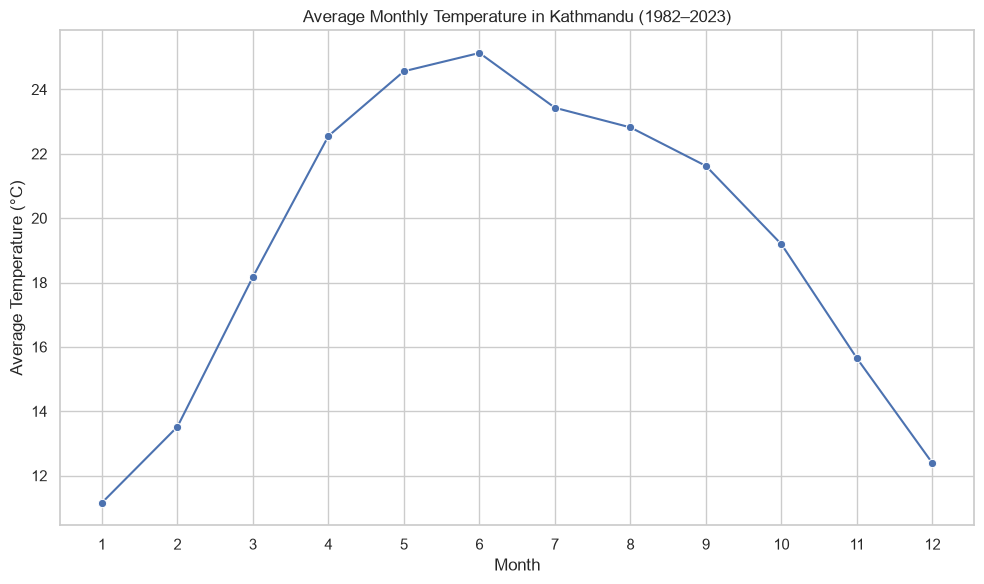

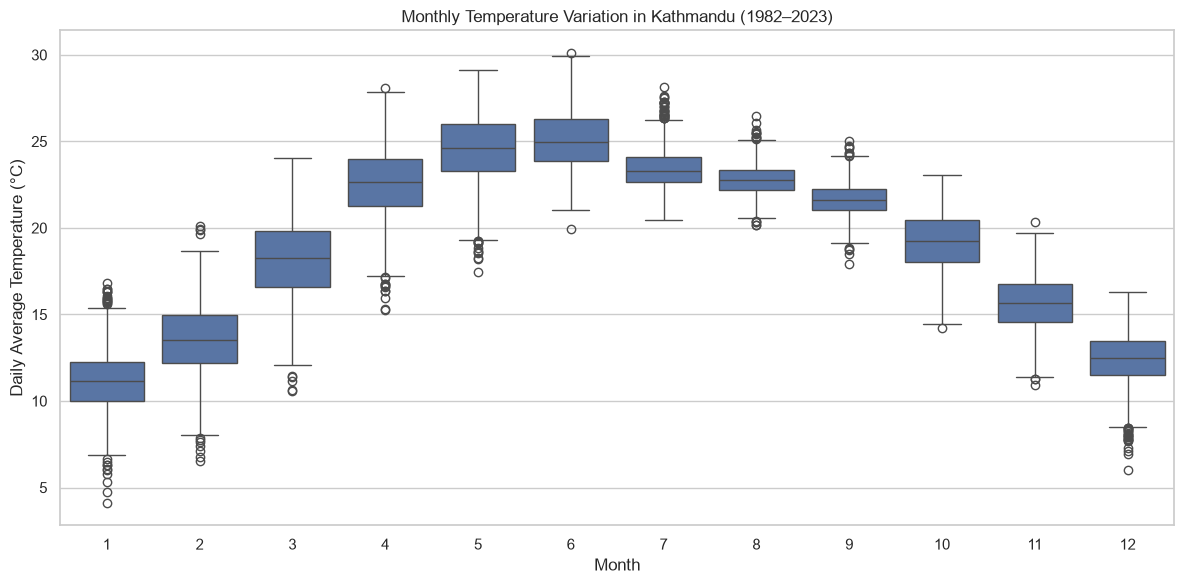

Both monthly temperature figures saved successfully.


In [7]:
# Extract month from the date
df["MONTH"] = df["DATE"].dt.month

# Calculate average temperature for each month
monthly_temperature = df.groupby("MONTH")["T2M"].mean()

# Display monthly averages
print("Average Daily Temperature by Month:")
print(monthly_temperature.round(2))

print("\nWarmest month:", monthly_temperature.idxmax(),
      "-", round(monthly_temperature.max(), 2), "°C")

print("Coldest month:", monthly_temperature.idxmin(),
      "-", round(monthly_temperature.min(), 2), "°C")


# Plot monthly average temperature
plt.figure(figsize=(10, 6))

sns.lineplot(
    x=monthly_temperature.index,
    y=monthly_temperature.values,
    marker="o"
)

plt.title("Average Monthly Temperature in Kathmandu (1982–2023)")
plt.xlabel("Month")
plt.ylabel("Average Temperature (°C)")
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()

plt.savefig(
    output_dir / "monthly_average_temperature.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Plot monthly temperature variation
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="MONTH",
    y="T2M"
)

plt.title("Monthly Temperature Variation in Kathmandu (1982–2023)")
plt.xlabel("Month")
plt.ylabel("Daily Average Temperature (°C)")
plt.tight_layout()

plt.savefig(
    output_dir / "monthly_temperature_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Both monthly temperature figures saved successfully.")

Correlation with daily average temperature (T2M):
T2M            1.000
TS             0.989
T2M_MIN        0.956
T2M_MAX        0.940
T2MWET         0.836
QV2M           0.628
WS2M           0.433
WS10M          0.389
RH2M           0.261
PRECTOTCORR    0.253
WS2M_RANGE     0.220
WS2M_MAX       0.220
WS10M_MAX      0.190
WS10M_RANGE    0.164
WS10M_MIN      0.107
WS2M_MIN       0.061
T2M_RANGE     -0.136
PS            -0.751
Name: T2M, dtype: float64


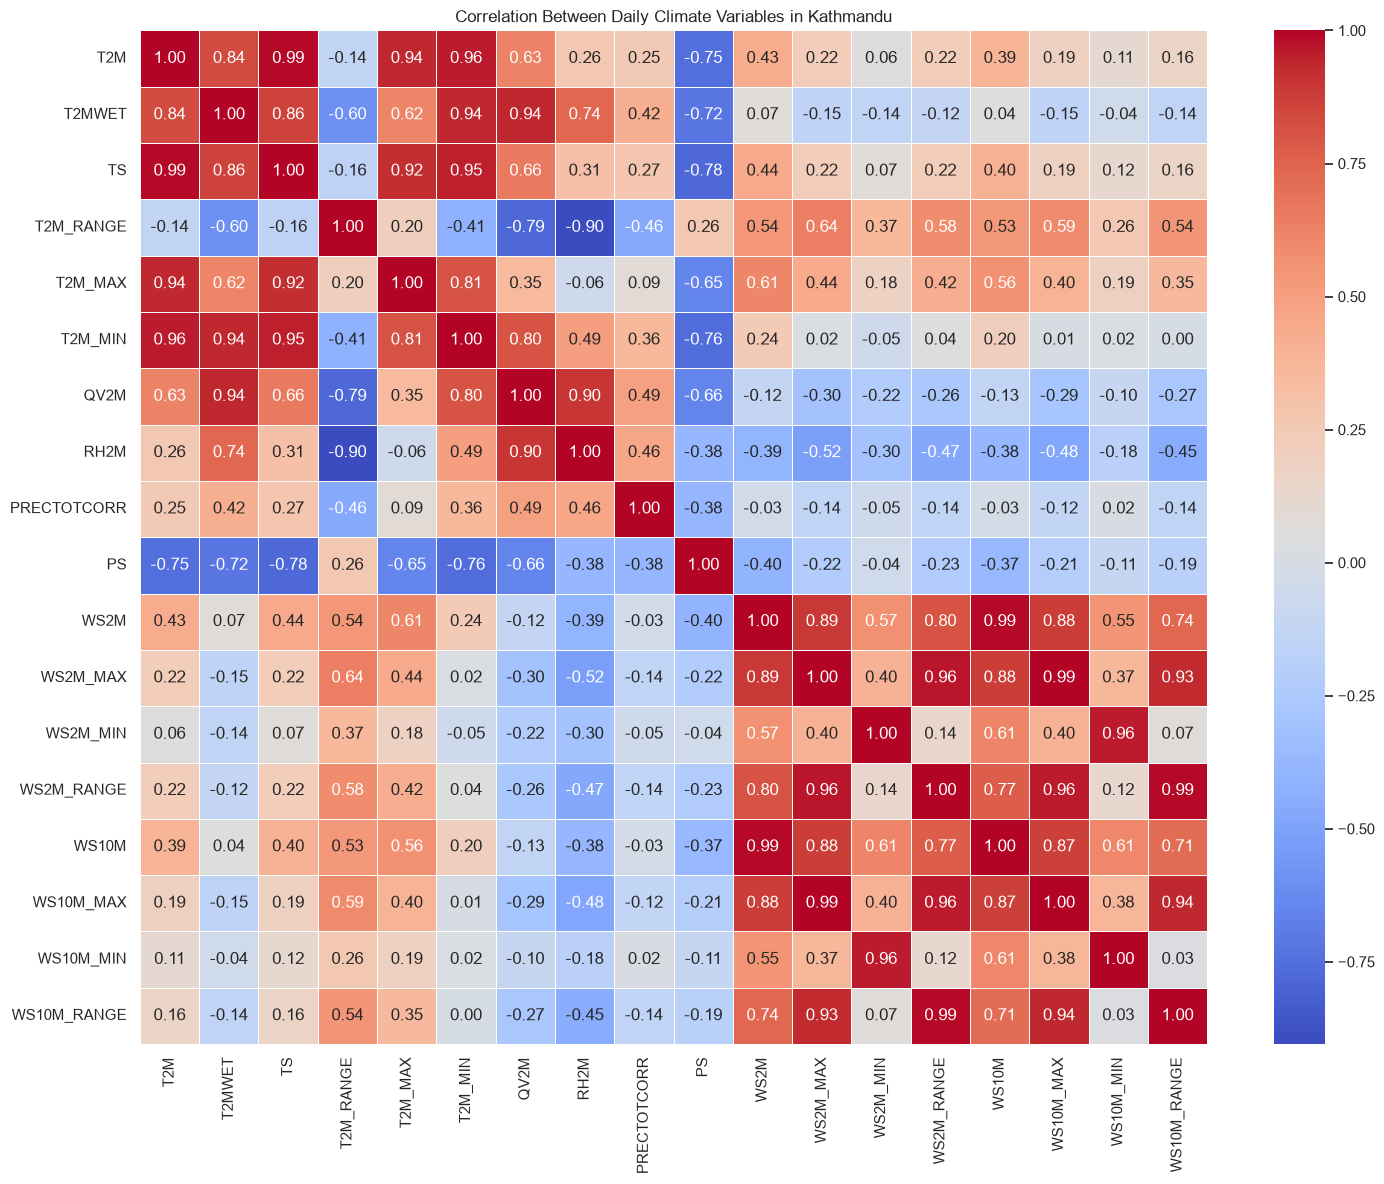

Correlation heatmap saved successfully.


In [8]:
# Select numerical climate variables
climate_columns = [
    "T2M", "T2MWET", "TS", "T2M_RANGE",
    "T2M_MAX", "T2M_MIN", "QV2M", "RH2M",
    "PRECTOTCORR", "PS", "WS2M", "WS2M_MAX",
    "WS2M_MIN", "WS2M_RANGE", "WS10M",
    "WS10M_MAX", "WS10M_MIN", "WS10M_RANGE"
]

# Calculate correlation matrix
correlation_matrix = df[climate_columns].corr()

# Display correlation with target temperature
print("Correlation with daily average temperature (T2M):")
print(
    correlation_matrix["T2M"]
    .sort_values(ascending=False)
    .round(3)
)

# Create correlation heatmap
plt.figure(figsize=(15, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Daily Climate Variables in Kathmandu")
plt.tight_layout()

plt.savefig(
    output_dir / "climate_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Correlation heatmap saved successfully.")

Annual Temperature Summary
--------------------------
Lowest annual average: 18.37 °C in 2020
Highest annual average: 20.1 °C in 1999
First year average: 18.94 °C
Last year average: 19.28 °C


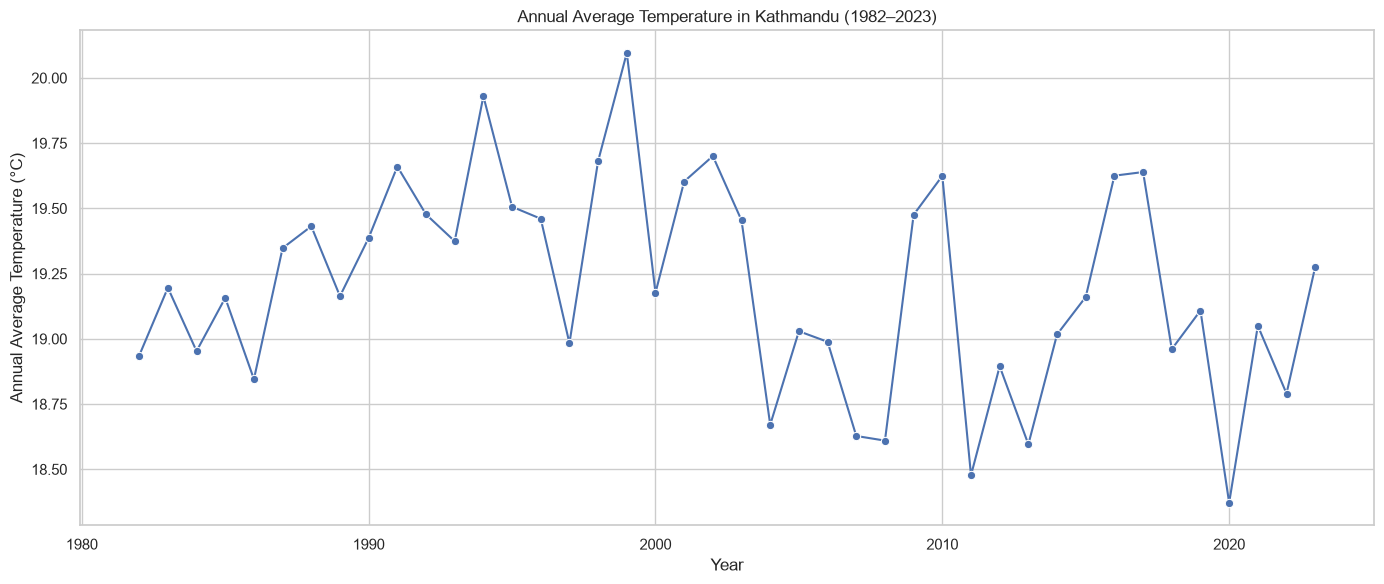

Annual temperature trend figure saved successfully.


In [9]:
# Calculate annual average temperature
annual_temperature = df.groupby("YEAR")["T2M"].mean()

# Display summary
print("Annual Temperature Summary")
print("--------------------------")
print("Lowest annual average:",
      round(annual_temperature.min(), 2), "°C",
      "in", annual_temperature.idxmin())

print("Highest annual average:",
      round(annual_temperature.max(), 2), "°C",
      "in", annual_temperature.idxmax())

print("First year average:",
      round(annual_temperature.iloc[0], 2), "°C")

print("Last year average:",
      round(annual_temperature.iloc[-1], 2), "°C")


# Plot annual average temperature
plt.figure(figsize=(14, 6))

sns.lineplot(
    x=annual_temperature.index,
    y=annual_temperature.values,
    marker="o"
)

plt.title("Annual Average Temperature in Kathmandu (1982–2023)")
plt.xlabel("Year")
plt.ylabel("Annual Average Temperature (°C)")
plt.grid(True)
plt.tight_layout()

plt.savefig(
    output_dir / "annual_temperature_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Annual temperature trend figure saved successfully.")

In [10]:
# Find the coldest and warmest recorded days
coldest_day = df.loc[df["T2M"].idxmin()]
warmest_day = df.loc[df["T2M"].idxmax()]

print("Coldest Recorded Day")
print("--------------------")
print("Date:", coldest_day["DATE"].date())
print("Temperature:", coldest_day["T2M"], "°C")

print("\nWarmest Recorded Day")
print("--------------------")
print("Date:", warmest_day["DATE"].date())
print("Temperature:", warmest_day["T2M"], "°C")

# Display the 5 coldest and 5 warmest observations
print("\nFive Coldest Days:")
display(df.nsmallest(5, "T2M")[["DATE", "T2M"]])

print("\nFive Warmest Days:")
display(df.nlargest(5, "T2M")[["DATE", "T2M"]])

Coldest Recorded Day
--------------------
Date: 2013-01-08
Temperature: 4.12 °C

Warmest Recorded Day
--------------------
Date: 1998-06-10
Temperature: 30.11 °C

Five Coldest Days:


,DATE,T2M
11330,2013-01-08,4.12
11331,2013-01-09,4.76
11332,2013-01-10,5.32
11329,2013-01-07,5.81
8031,2003-12-28,6.00



Five Warmest Days:


,DATE,T2M
6004,1998-06-10,30.11
11123,2012-06-15,29.92
1994,1987-06-18,29.90
11122,2012-06-14,29.82
6003,1998-06-09,29.54


Current Day vs Next Day Temperature
-----------------------------------
Correlation: 0.9864


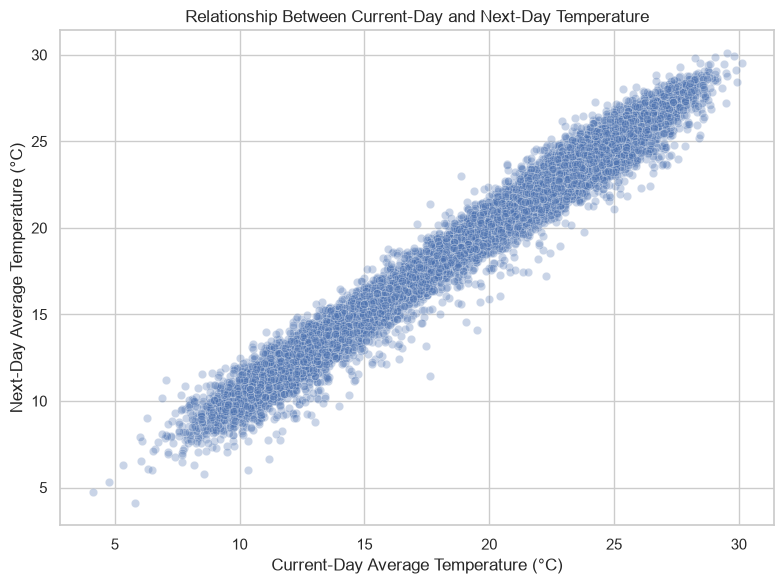

Current vs next-day temperature figure saved successfully.


In [11]:
# Create a next-day temperature column for EDA
df["NEXT_DAY_T2M"] = df["T2M"].shift(-1)

# Calculate correlation
next_day_correlation = df["T2M"].corr(df["NEXT_DAY_T2M"])

print("Current Day vs Next Day Temperature")
print("-----------------------------------")
print("Correlation:", round(next_day_correlation, 4))

# Scatter plot
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="T2M",
    y="NEXT_DAY_T2M",
    alpha=0.3
)

plt.title("Relationship Between Current-Day and Next-Day Temperature")
plt.xlabel("Current-Day Average Temperature (°C)")
plt.ylabel("Next-Day Average Temperature (°C)")
plt.grid(True)
plt.tight_layout()

plt.savefig(
    output_dir / "current_vs_next_day_temperature.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Current vs next-day temperature figure saved successfully.")

Top 10 Important Features
-------------------------


,Feature,Importance
18,T2M_LAG_1,0.241827
0,T2M,0.171101
2,TS,0.161953
21,T2M_ROLLING_3,0.082119
19,T2M_LAG_2,0.078470
22,T2M_ROLLING_7,0.061236
20,T2M_LAG_3,0.044770
5,T2M_MIN,0.042724
24,NEXT_DAY_DOY_COS,0.034375
4,T2M_MAX,0.031711


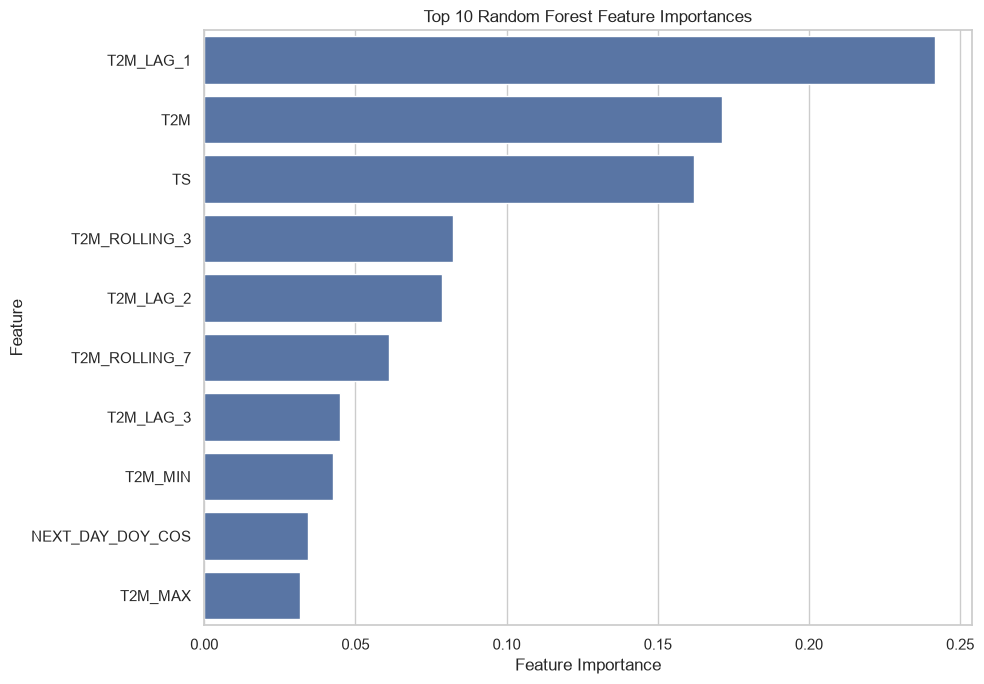

Feature importance figure saved successfully.


In [13]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Locate the project root
project_root = Path.cwd().parent

# Load the trained Random Forest model
model_path = project_root / "outputs" / "models" / "random_forest_best.joblib"

rf_model = joblib.load(model_path)

# Extract the Random Forest estimator
if hasattr(rf_model, "named_steps"):
    rf_estimator = list(rf_model.named_steps.values())[-1]
else:
    rf_estimator = rf_model

# Extract feature importance
feature_names = rf_estimator.feature_names_in_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_estimator.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 10 Important Features")
print("-------------------------")
display(importance_df.head(10))

# Plot feature importance
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Random Forest Feature Importances")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig(
    project_root / "outputs" / "figures" /
    "random_forest_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Feature importance figure saved successfully.")

In [14]:
import json
from pathlib import Path

project_root = Path.cwd().parent
results_folder = project_root / "outputs" / "results"

files_to_check = [
    "random_forest_results.json",
    "ridge_results.json",
    "lasso_results.json",
    "final_test_results.json",
    "baseline_results.csv",
    "final_model_comparison.csv"
]

for filename in files_to_check:
    file_path = results_folder / filename

    print(f"\n{'=' * 55}")
    print(filename)
    print("=" * 55)

    if file_path.exists():
        if filename.endswith(".json"):
            with open(file_path, "r") as file:
                print(json.dumps(json.load(file), indent=4))
        else:
            import pandas as pd
            display(pd.read_csv(file_path))
    else:
        print("File not found.")


random_forest_results.json
{
    "best_parameters": {
        "max_depth": null,
        "max_features": "sqrt",
        "min_samples_leaf": 2,
        "min_samples_split": 5,
        "n_estimators": 200
    },
    "best_cv_rmse": 0.7947192083504401,
    "validation_metrics": {
        "MAE": 0.5761313879468788,
        "MSE": 0.6006807944636446,
        "RMSE": 0.7750359955922336,
        "R2": 0.9762492449257758
    }
}

ridge_results.json
{
    "best_parameters": {
        "model__alpha": 0.1
    },
    "best_cv_rmse": 0.7807055134754943,
    "validation_metrics": {
        "MAE": 0.567088783727284,
        "MSE": 0.5821338585116508,
        "RMSE": 0.762976971154209,
        "R2": 0.9769825857238056
    }
}

lasso_results.json
{
    "best_parameters": {
        "model__alpha": 0.0001
    },
    "best_cv_rmse": 0.7805546472802807,
    "validation_metrics": {
        "MAE": 0.5667978592345967,
        "MSE": 0.5816672108230965,
        "RMSE": 0.7626711026537563,
        "R2": 0.977

,MAE,MSE,RMSE,R2
0,0.617004,0.672477,0.820047,0.970579



final_model_comparison.csv


,Model,MAE,MSE,RMSE,R2
0,Random Forest,0.580843,0.597414,0.772926,0.973863
1,Lasso,0.580778,0.600365,0.774832,0.973734
2,Ridge,0.580909,0.601052,0.775275,0.973704
3,Persistence Baseline,0.617004,0.672477,0.820047,0.970579


In [15]:
import json
from pathlib import Path

project_root = Path.cwd().parent
results_folder = project_root / "outputs" / "results"

models = [
    "random_forest",
    "ridge",
    "lasso"
]

for model in models:
    file_path = results_folder / f"{model}_results.json"

    with open(file_path, "r") as file:
        results = json.load(file)

    print(f"\n{model.upper()}")
    print("-" * 40)
    print("Best parameters:", results["best_parameters"])
    print("Best CV RMSE:", results["best_cv_rmse"])
    print("Validation metrics:", results["validation_metrics"])


RANDOM_FOREST
----------------------------------------
Best parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
Best CV RMSE: 0.7947192083504401
Validation metrics: {'MAE': 0.5761313879468788, 'MSE': 0.6006807944636446, 'RMSE': 0.7750359955922336, 'R2': 0.9762492449257758}

RIDGE
----------------------------------------
Best parameters: {'model__alpha': 0.1}
Best CV RMSE: 0.7807055134754943
Validation metrics: {'MAE': 0.567088783727284, 'MSE': 0.5821338585116508, 'RMSE': 0.762976971154209, 'R2': 0.9769825857238056}

LASSO
----------------------------------------
Best parameters: {'model__alpha': 0.0001}
Best CV RMSE: 0.7805546472802807
Validation metrics: {'MAE': 0.5667978592345967, 'MSE': 0.5816672108230965, 'RMSE': 0.7626711026537563, 'R2': 0.9770010368463634}
